In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
concrete_compressive_strength = fetch_ucirepo(id=165) 
  
# data (as pandas dataframes) 
X_df = concrete_compressive_strength.data.features 
y_df = concrete_compressive_strength.data.targets 
  
# metadata 
print(concrete_compressive_strength.metadata) 
  
# variable information 
print(concrete_compressive_strength.variables) 

{'uci_id': 165, 'name': 'Concrete Compressive Strength', 'repository_url': 'https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength', 'data_url': 'https://archive.ics.uci.edu/static/public/165/data.csv', 'abstract': 'Concrete is the most important material in civil engineering. The concrete compressive strength is a highly nonlinear function of age and ingredients. ', 'area': 'Physics and Chemistry', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1030, 'num_features': 8, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Concrete compressive strength'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sun Feb 11 2024', 'dataset_doi': '10.24432/C5PK67', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 383, 'type': 'NATIVE', 'title': 'Modeling of strength of high-performance concrete using artificial neural networks', 'authors': 'I. Yeh', 'venue': 'C

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def f(X, W, b):
    return X @ W + b

def mse(X, y, W, b):
    return np.mean((f(X, W, b) - y) ** 2)

def dW(X, y, W, b):
    return (2 / len(X)) * (X.T @ (f(X, W, b) - y))
    
def db(X, y, W, b):
    return 2 * np.mean((f(X, W, b) - y))

def var(y):
    return np.mean((np.mean(y) - y) ** 2)

def r2(X, y, W, b):
    return 1 - mse(X, y, W, b) / var(y)

def gradient_descent(initial_W, initial_b, X, y, lr, iterations):
    if X.ndim == 1:
        X = X.reshape(-1, 1)
        
    W = np.asarray(initial_W, dtype=float).reshape(-1, 1).copy()
    b = initial_b

    mse_over_time = []
    r2_over_time = []

    for i in range(iterations):
        W, b = W - lr * dW(X, y, W, b), b - lr * db(X, y, W, b)
        
        mse_over_time.append(mse(X, y, W, b))
        r2_over_time.append(r2(X, y, W, b))

    return W, b, mse_over_time, r2_over_time

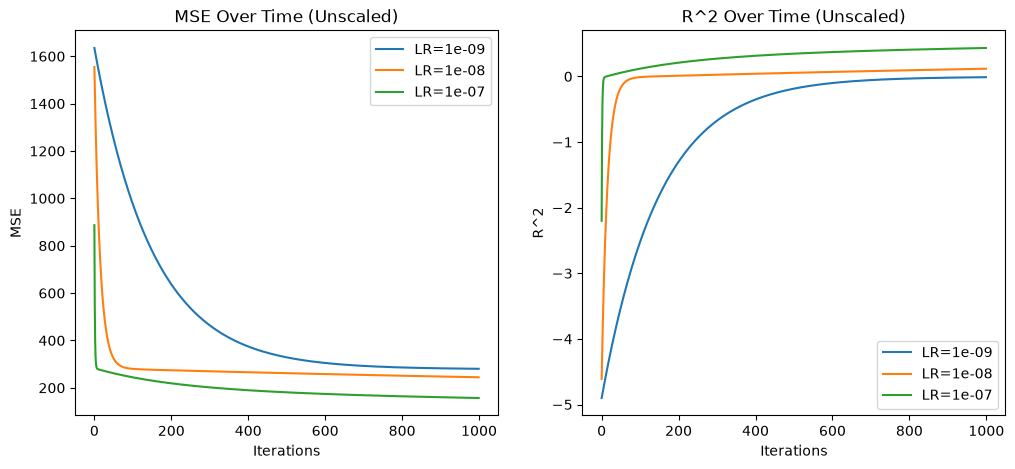

MSE on test set: 225.64838604122554
R^2 on test set: -0.03632412218550485


In [26]:
selected_features = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water", "Superplasticizer", "Coarse Aggregate", "Fine Aggregate", "Age"]
                    
X_df_selected = X_df[selected_features]
X_test = X_df_selected.iloc[501:631].to_numpy()
y_test = y_df.iloc[501:631].to_numpy()
X_train = pd.concat([X_df_selected.iloc[:501], X_df_selected.iloc[631:]]).to_numpy()
y_train = pd.concat([y_df.iloc[:501], y_df.iloc[631:]]).to_numpy()

lrs = [1e-9, 1e-8, 1e-7]
initial_W = np.zeros((len(selected_features), 1))
initial_b = 0
iterations = 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title("MSE Over Time (Unscaled)")
ax2.set_title("R^2 Over Time (Unscaled)")
ax1.set_xlabel("Iterations")
ax2.set_xlabel("Iterations")
ax1.set_ylabel("MSE")
ax2.set_ylabel("R^2")

for lr in lrs:
    W, b, mse_over_time, r2_over_time = gradient_descent(initial_W, initial_b, X_train, y_train, lr, iterations)
    
    ax1.plot(mse_over_time, label=f"LR={lr}")
    ax2.plot(r2_over_time, label=f"LR={lr}")

ax1.legend()
ax2.legend()
plt.show()

print(f"MSE on test set: {mse(X_test, y_test, W, b)}")
print(f"R^2 on test set: {r2(X_test, y_test, W, b)}")

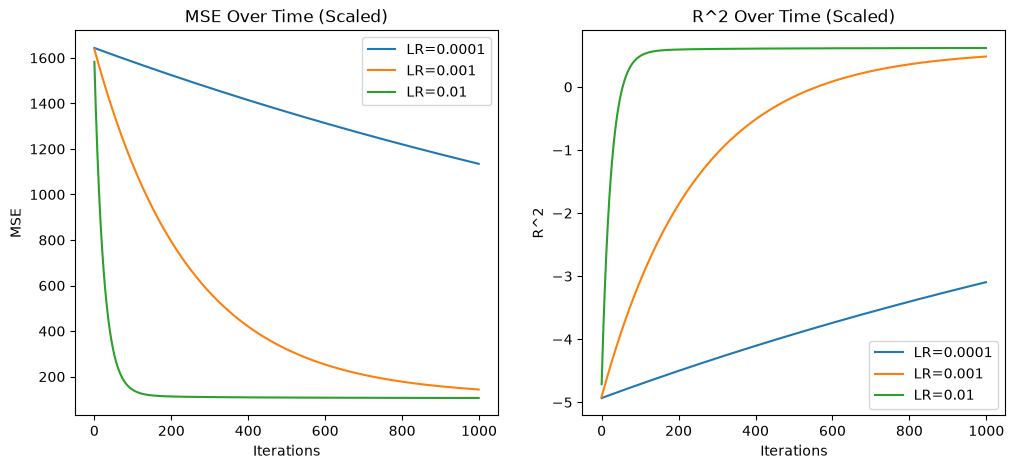

MSE on test set (scaled): 133.0434571754113
R^2 on test set (scaled): 0.3889779298282098


In [5]:
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1
X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

lrs = [1e-4, 1e-3, 1e-2]
initial_W = np.zeros((len(selected_features), 1))
initial_b = 0
iterations = 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title("MSE Over Time (Scaled)")
ax2.set_title("R^2 Over Time (Scaled)")
ax1.set_xlabel("Iterations")
ax2.set_xlabel("Iterations")
ax1.set_ylabel("MSE")
ax2.set_ylabel("R^2")

for lr in lrs:
    W_scaled, b_scaled, mse_over_time_scaled, r2_over_time_scaled = gradient_descent(initial_W, initial_b, X_train_scaled, y_train, lr, iterations)
    
    ax1.plot(mse_over_time_scaled, label=f"LR={lr}")
    ax2.plot(r2_over_time_scaled, label=f"LR={lr}")

ax1.legend()
ax2.legend()
plt.show()

print(f"MSE on test set (scaled): {mse(X_test_scaled, y_test, W_scaled, b_scaled)}")
print(f"R^2 on test set (scaled): {r2(X_test_scaled, y_test, W_scaled, b_scaled)}")

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test)
y_pred_scaled = model_scaled.predict(X_test_scaled)

print(f"MSE on test set: {mean_squared_error(y_test, y_pred)}")
print(f"R^2 on test set: {r2_score(y_test, y_pred)}")
print(f"MSE on test set (scaled): {mean_squared_error(y_test, y_pred_scaled)}")
print(f"R^2 on test set (scaled): {r2_score(y_test, y_pred_scaled)}")

MSE on test set: 141.25799330049728
R^2 on test set: 0.35125143823506555
MSE on test set (scaled): 141.2579933004976
R^2 on test set (scaled): 0.3512514382350641


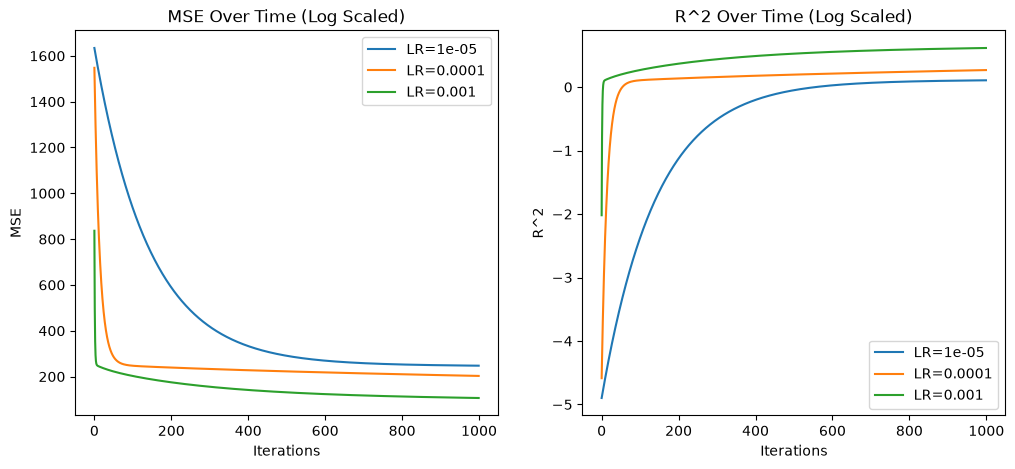

MSE on test set (log scaled): 129.17263767403713
R^2 on test set (log scaled): 0.40675525007532753


In [8]:
X_train_log_scaled = np.log(X_train + 1)
X_test_log_scaled = np.log(X_test + 1)

lrs = [1e-5, 1e-4, 1e-3]
initial_W = np.zeros((len(selected_features), 1))
initial_b = 0
iterations = 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title("MSE Over Time (Log Scaled)")
ax2.set_title("R^2 Over Time (Log Scaled)")
ax1.set_xlabel("Iterations")
ax2.set_xlabel("Iterations")
ax1.set_ylabel("MSE")
ax2.set_ylabel("R^2")

for lr in lrs:
    W_log_scaled, b_log_scaled, mse_over_time_log_scaled, r2_over_time_log_scaled = gradient_descent(initial_W, initial_b, X_train_log_scaled, y_train, lr, iterations)
    
    ax1.plot(mse_over_time_log_scaled, label=f"LR={lr}")
    ax2.plot(r2_over_time_log_scaled, label=f"LR={lr}")

ax1.legend()
ax2.legend()
plt.show()

print(f"MSE on test set (log scaled): {mse(X_test_log_scaled, y_test, W_log_scaled, b_log_scaled)}")
print(f"R^2 on test set (log scaled): {r2(X_test_log_scaled, y_test, W_log_scaled, b_log_scaled)}")

In [9]:
model_log_scaled = LinearRegression()
model_log_scaled.fit(X_train_log_scaled, y_train)
y_pred_log_scaled = model_log_scaled.predict(X_test_log_scaled)

print(f"MSE on test set (log scaled): {mean_squared_error(y_test, y_pred_log_scaled)}")
print(f"R^2 on test set (log scaled): {r2_score(y_test, y_pred_log_scaled)}")

MSE on test set (log scaled): 54.51984726570458
R^2 on test set (log scaled): 0.7496094084670448


In [10]:
y_train_pred = model.predict(X_train)
y_train_pred_scaled = model_scaled.predict(X_train_scaled)
y_train_pred_log_scaled = model_log_scaled.predict(X_train_log_scaled)

summary_data = {
    "Model": ["Untransformed", "Standardized", "Log-Transformed"],
    "Training MSE": [
        mean_squared_error(y_train, y_train_pred),
        mean_squared_error(y_train, y_train_pred_scaled),
        mean_squared_error(y_train, y_train_pred_log_scaled)
    ],
    "Testing MSE": [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred_scaled),
        mean_squared_error(y_test, y_pred_log_scaled)
    ],
    "Training R^2": [
        r2_score(y_train, y_train_pred),
        r2_score(y_train, y_train_pred_scaled),
        r2_score(y_train, y_train_pred_log_scaled)
    ],
    "Testing R^2": [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_scaled),
        r2_score(y_test, y_pred_log_scaled)
    ]
}

summary_df = pd.DataFrame(summary_data)
summary_df.set_index("Model", inplace=True)
summary_df

,Training MSE,Testing MSE,Training R^2,Testing R^2
Model,,,,
Untransformed,104.154464,141.257993,0.624100,0.351251
Standardized,104.154464,141.257993,0.624100,0.351251
Log-Transformed,55.831489,54.519847,0.798501,0.749609


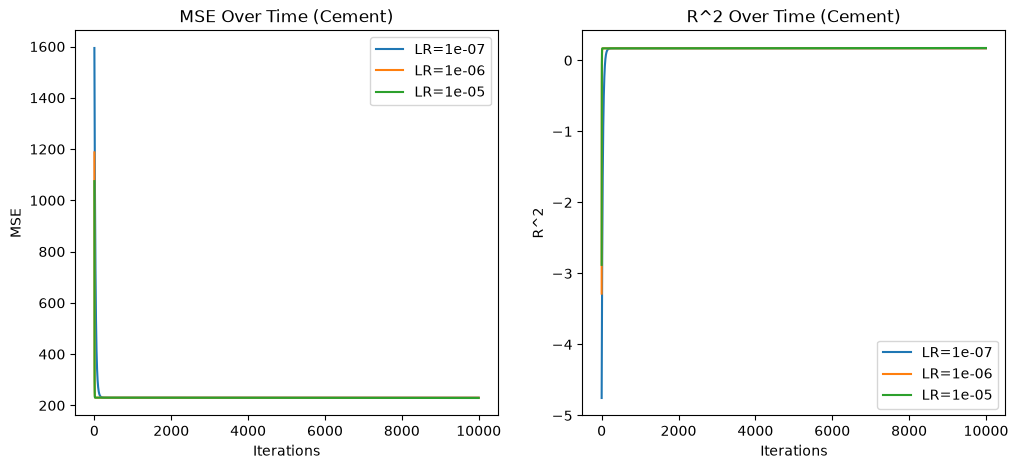

MSE on test set: 256.64766540321466
R^2 on test set: -0.17869297106939364


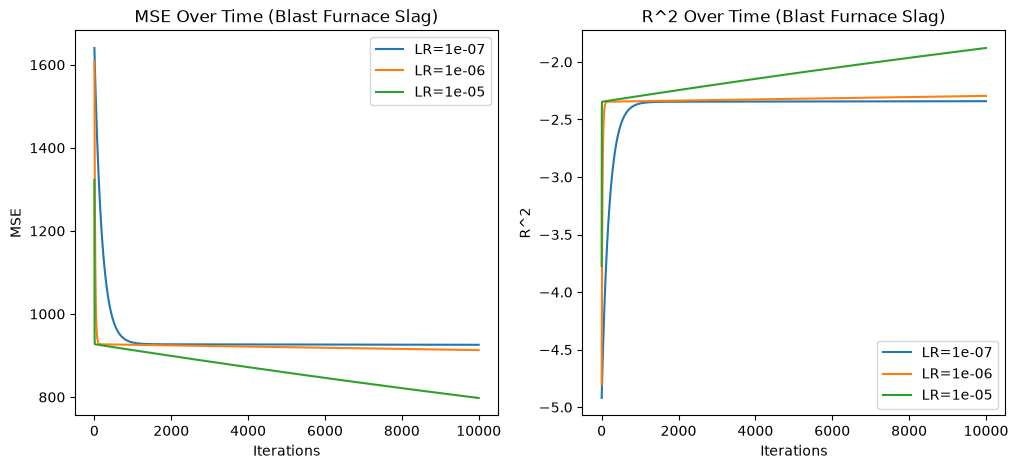

MSE on test set: 861.54596762295
R^2 on test set: -2.956779325052184


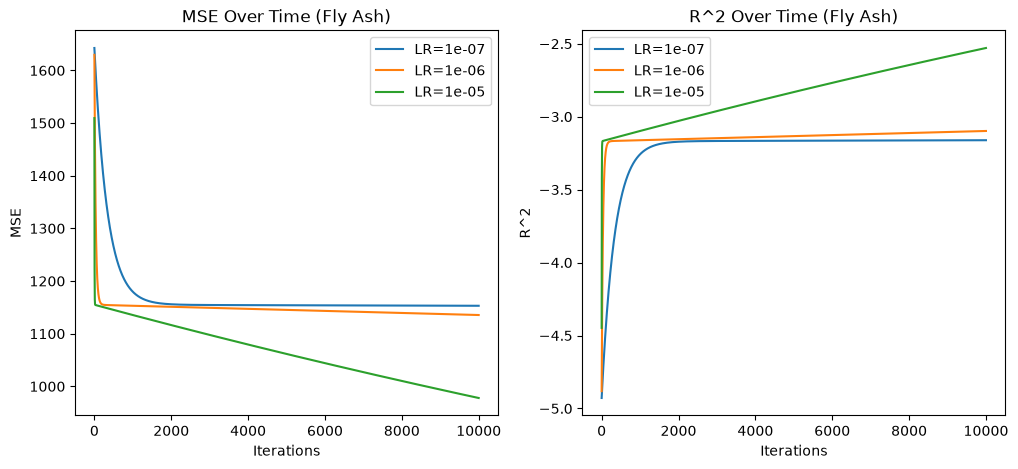

MSE on test set: 470.5674920022762
R^2 on test set: -1.1611519215085315


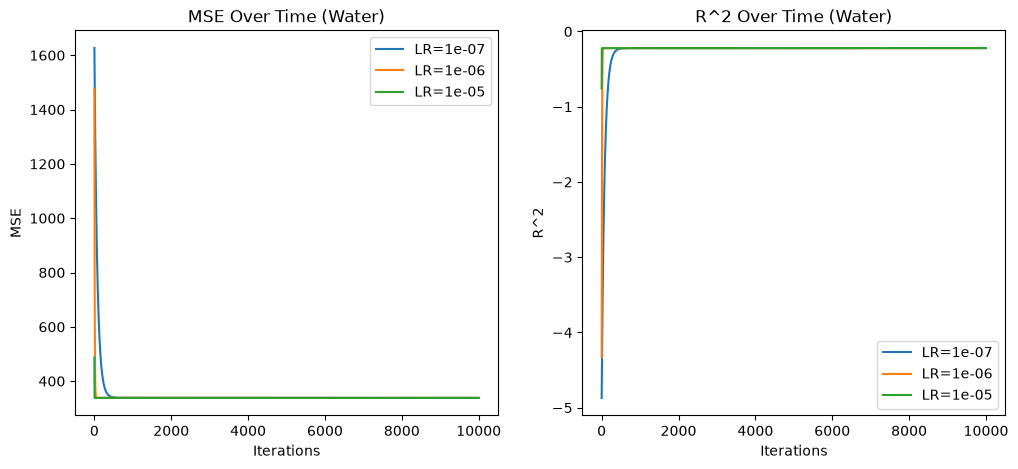

MSE on test set: 333.0873786845797
R^2 on test set: -0.5297538412851885


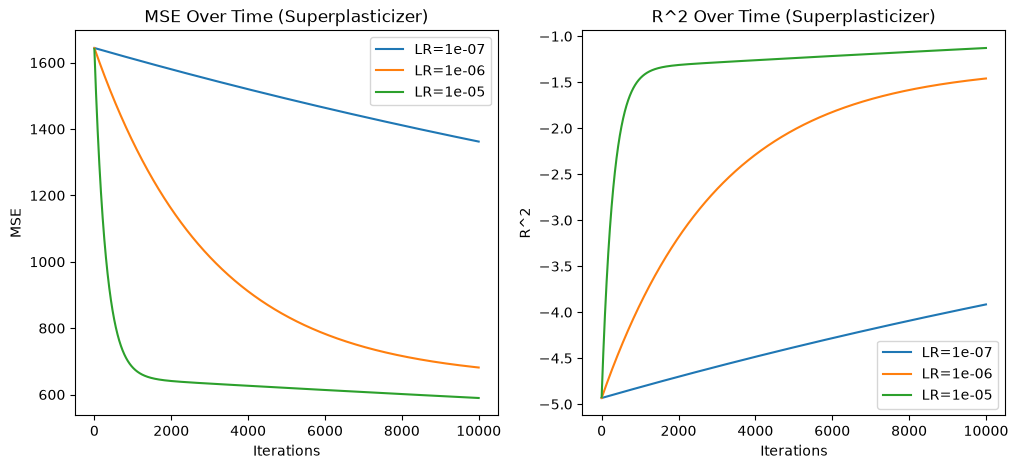

MSE on test set: 540.9605166798073
R^2 on test set: -1.484442465645626


/home/kevin/data-mining-project-1/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_37900/2073283005.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((f(X, W, b) - y) ** 2)
/tmp/ipykernel_37900/2073283005.py:8: RuntimeWarning: overflow encountered in matmul
  return (2 / len(X)) * (X.T @ (f(X, W, b) - y))
/tmp/ipykernel_37900/2073283005.py:30: RuntimeWarning: invalid value encountered in subtract
  W, b = W - lr * dW(X, y, W, b), b - lr * db(X, y, W, b)


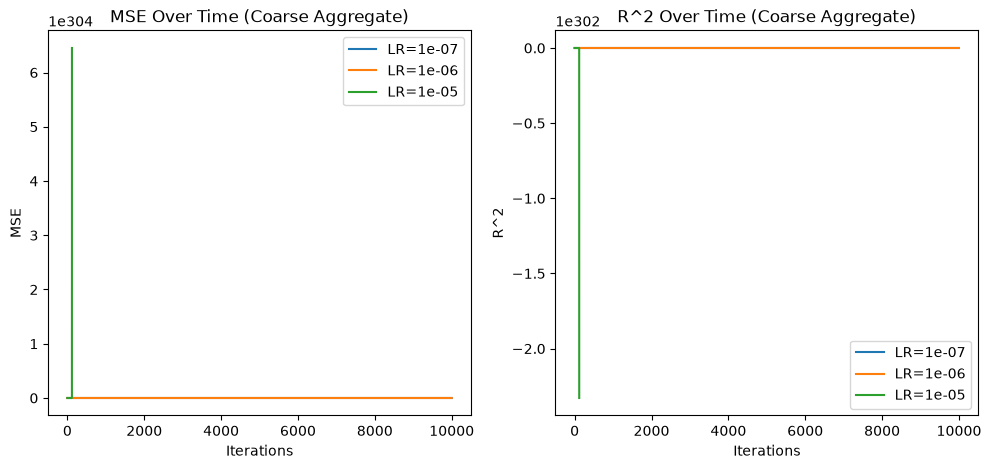

MSE on test set: nan
R^2 on test set: nan


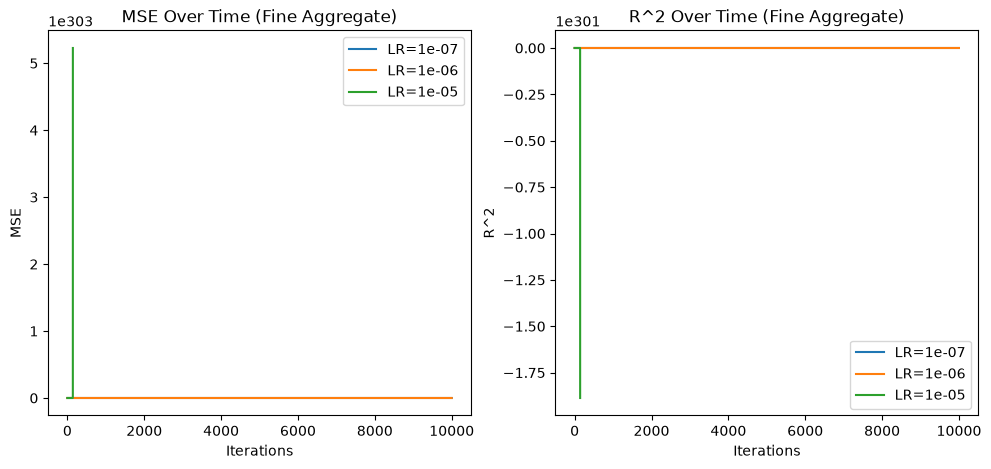

MSE on test set: nan
R^2 on test set: nan


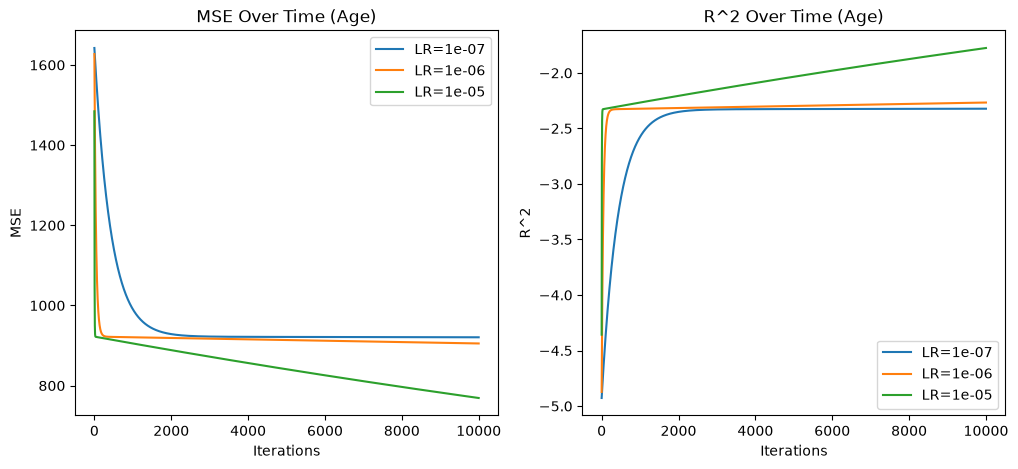

MSE on test set: 729.3783698722137
R^2 on test set: -2.349779770907911


In [29]:
for i, feature in enumerate(selected_features):
    X_train_feature = X_train[:, [i]]
    X_test_feature = X_test[:, [i]]

    lrs = [1e-7, 1e-6, 1e-5]
    initial_W = np.zeros((1, 1))
    initial_b = 0
    iterations = 10000
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.set_title(f"MSE Over Time ({feature})")
    ax2.set_title(f"R^2 Over Time ({feature})")
    ax1.set_xlabel("Iterations")
    ax2.set_xlabel("Iterations")
    ax1.set_ylabel("MSE")
    ax2.set_ylabel("R^2")
    
    for lr in lrs:
        W, b, mse_over_time, r2_over_time = gradient_descent(initial_W, initial_b, X_train_feature, y_train, lr, iterations)
        
        ax1.plot(mse_over_time, label=f"LR={lr}")
        ax2.plot(r2_over_time, label=f"LR={lr}")
    
    ax1.legend()
    ax2.legend()
    plt.show()
    
    print(f"MSE on test set: {mse(X_test_feature, y_test, W, b)}")
    print(f"R^2 on test set: {r2(X_test_feature, y_test, W, b)}")
    

In [12]:
multivariate_coefficients = model.coef_.reshape(-1)
individual_feature_coefficients = []

for i, feature in enumerate(selected_features):
    X_train_feature = X_train[:, [i]]

    model_feature = LinearRegression()
    model_feature.fit(X_train_feature, y_train)
    individual_feature_coefficients.append(model_feature.coef_.item())

coeff_data = {
    "Feature": selected_features,
    "Multivariate Coefficient": multivariate_coefficients,
    "Individual Coefficient": individual_feature_coefficients
}

coeff_df = pd.DataFrame(coeff_data)
coeff_df.set_index("Feature", inplace=True)
coeff_df

,Multivariate Coefficient,Individual Coefficient
Feature,,
Cement,0.132845,0.080784
Blast Furnace Slag,0.125040,0.031215
Fly Ash,0.106739,-0.053323
Water,-0.133135,-0.205895
Superplasticizer,0.116182,0.883056
Coarse Aggregate,0.028633,-0.027449
Fine Aggregate,0.034084,-0.030628
Age,0.118763,0.094991


In [13]:
import statsmodels.api as sm

In [22]:
X_train_const = sm.add_constant(X_train)
X_train_scaled_const = sm.add_constant(X_train_scaled)
X_train_log_scaled_const = sm.add_constant(X_train_log_scaled)

model = sm.OLS(y_train, X_train_const).fit()
model_scaled = sm.OLS(y_train, X_train_scaled_const).fit()
model_log_scaled = sm.OLS(y_train, X_train_log_scaled_const).fit()

p_values_df = pd.DataFrame(
    {
        "Feature": selected_features,
        "Untransformed": model.pvalues[1:],
        "Standardized": model_scaled.pvalues[1:],
        "Log-Transformed": model_log_scaled.pvalues[1:],
    }
)
p_values_df.set_index("Feature", inplace=True)
p_values_df

,Untransformed,Standardized,Log-Transformed
Feature,,,
Cement,6.970969e-41,6.970969e-41,1.298605e-86
Blast Furnace Slag,4.145190e-26,4.145190e-26,4.518790e-36
Fly Ash,1.894571e-13,1.894571e-13,2.605347e-01
Water,1.918418e-03,1.918418e-03,1.862586e-20
Superplasticizer,2.461117e-01,2.461117e-01,1.039697e-05
Coarse Aggregate,5.443241e-03,5.443241e-03,4.078943e-01
Fine Aggregate,2.738122e-03,2.738122e-03,9.476866e-02
Age,9.516219e-74,9.516219e-74,1.746991e-192
